In [ ]:
!pip -q install segmentation-models-pytorch

In [42]:
import json, torch
import segmentation_models_pytorch as smp
from pathlib import Path
from torch.utils.data import DataLoader
from src.dataset import PolypDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with open("configs/splits.json") as f:
    splits = json.load(f)

image_dir = Path("data/Kvasir-SEG/images")

train_paths = [image_dir / filename for filename in splits["train"]]

# using just 16 images to test training
dataset = PolypDataset(train_paths[:16])

loader = DataLoader(dataset, batch_size=4, shuffle=True,)

# initialize unet with pretrained encoder
model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None,
).to(device)

# loss and optimizer
criterion = torch.nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4,)

# retrieve one batch
images, masks = next(iter(loader))

images = images.to(device)
masks = masks.to(device)

# normalize to the imagenet stats used by our pretrained encoder
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)

std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

images = (images - mean) / std

# one training step
model.train()

optimizer.zero_grad()

outputs = model(images)

loss = criterion(outputs, masks)
loss.backward()

optimizer.step()

print("Device:", device)
print("Output shape:", outputs.shape)
print("Training loss:", loss.item())

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda
Output shape: torch.Size([4, 1, 256, 256])
Training loss: 0.5008974075317383


In [44]:
!python -m src.test_dataset
!python -m src.test_model

Image: torch.Size([3, 256, 256]) torch.float32
Mask: torch.Size([1, 256, 256]) torch.float32
Batch images: torch.Size([8, 3, 256, 256])
Batch masks: torch.Size([8, 1, 256, 256])
Input: torch.Size([1, 3, 256, 256])
Output: torch.Size([1, 1, 256, 256])


In [45]:
import csv, json, random
from pathlib import Path
import numpy as np, torch
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader
from src.dataset import PolypDataset

ROOT = Path("data/Kvasir-SEG/images")
DRIVE_ROOT = Path("/content/drive/MyDrive/polyp-segmentation")

CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
RESULTS_DIR = DRIVE_ROOT / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 5
BATCH_SIZE = 8
LEARNING_RATE = 1e-4
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)


with open("configs/splits.json") as f:
    splits = json.load(f)

train_paths = [ROOT / name for name in splits["train"]]
val_paths = [ROOT / name for name in splits["val"]]

train_loader = DataLoader(
    PolypDataset(train_paths),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader = DataLoader(
    PolypDataset(val_paths),
    batch_size=BATCH_SIZE,
    shuffle=False,
)


# model, loss, optimizer
model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None,
).to(device)

criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0.0
    dice_total = 0.0
    iou_total = 0.0
    num_samples = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        # normalizing RGB channels for pretrained encoder
        images = (images - mean) / std

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        # measuring segmentation quality without gradients
        with torch.no_grad():
            predicted = logits > 0
            target = masks > 0.5

            intersection = (predicted & target).sum(dim=(1, 2, 3))
            predicted_pixels = predicted.sum(dim=(1, 2, 3))
            target_pixels = target.sum(dim=(1, 2, 3))

            eps = 1e-7

            dice = (2 * intersection + eps) / (
                predicted_pixels + target_pixels + eps
            )

            iou = (intersection + eps) / (
                predicted_pixels + target_pixels - intersection + eps
            )

            n = images.size(0)
            total_loss += loss.item() * n
            dice_total += dice.sum().item()
            iou_total += iou.sum().item()
            num_samples += n

    return {
        "loss": total_loss / num_samples,
        "dice": dice_total / num_samples,
        "iou": iou_total / num_samples,
    }


# main training loop
best_dice = -1.0
history = []

for epoch in range(EPOCHS):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    record = {
        "epoch": epoch + 1,
        "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
        "val_dice": val_metrics["dice"],
        "val_iou": val_metrics["iou"],
    }
    history.append(record)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Dice: {val_metrics['dice']:.4f} | "
        f"IoU: {val_metrics['iou']:.4f}",
        flush=True,
    )

    # save the best validation checkpoint
    if val_metrics["dice"] > best_dice:
        best_dice = val_metrics["dice"]

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_dice": best_dice,
                "model_name": "unet_resnet18",
                "image_size": 256,
            },
            CHECKPOINT_DIR / "baseline_best.pt",
        )
        print("  Best checkpoint saved.", flush=True)

    # persist metrics after each epoch
    with open(RESULTS_DIR / "baseline_metrics.csv", "w") as f:
        writer = csv.DictWriter(f, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)

print("Training finished. Best validation Dice:", best_dice)


Training device: cuda
Epoch 1/5 | Train loss: 0.5094 | Val loss: 0.3463 | Dice: 0.7077 | IoU: 0.5850
  Best checkpoint saved.
Epoch 2/5 | Train loss: 0.2781 | Val loss: 0.2520 | Dice: 0.7985 | IoU: 0.6987
  Best checkpoint saved.
Epoch 3/5 | Train loss: 0.1902 | Val loss: 0.2064 | Dice: 0.8248 | IoU: 0.7286
  Best checkpoint saved.
Epoch 4/5 | Train loss: 0.1427 | Val loss: 0.1822 | Dice: 0.8495 | IoU: 0.7608
  Best checkpoint saved.
Epoch 5/5 | Train loss: 0.1098 | Val loss: 0.1646 | Dice: 0.8495 | IoU: 0.7637
  Best checkpoint saved.
Training finished. Best validation Dice: 0.8495151543617249


In [48]:
!python -u -m src.train_bce_dice

Training device: cuda
Epoch 1/5 | Train loss: 1.1650 | Val loss: 0.8538 | Dice: 0.7308 | IoU: 0.6016
  Best checkpoint saved.
Epoch 2/5 | Train loss: 0.7744 | Val loss: 0.6446 | Dice: 0.8158 | IoU: 0.7180
  Best checkpoint saved.
Epoch 3/5 | Train loss: 0.5688 | Val loss: 0.5356 | Dice: 0.8424 | IoU: 0.7488
  Best checkpoint saved.
Epoch 4/5 | Train loss: 0.4449 | Val loss: 0.4721 | Dice: 0.8503 | IoU: 0.7608
  Best checkpoint saved.
Epoch 5/5 | Train loss: 0.3517 | Val loss: 0.4194 | Dice: 0.8521 | IoU: 0.7675
  Best checkpoint saved.
Training finished. Best validation Dice: 0.8521432995796203


In [49]:
!python -u -m src.evaluate

Loaded checkpoint from epoch: 5
Test Dice: 0.8508
Test IoU:  0.7642

Five lowest-Dice images:
{'image': 'cju1dg44i4z3w0801nyz4p6zf.jpg', 'dice': 0.23085221648216248, 'iou': 0.13048779964447021}
{'image': 'cju84dsvaklpx098750hp83x4.jpg', 'dice': 0.3729717433452606, 'iou': 0.2292349487543106}
{'image': 'cju5yimthmlv80850zhoc90c2.jpg', 'dice': 0.37652358412742615, 'iou': 0.23192428052425385}
{'image': 'cju15ptjtppz40988odsm9azx.jpg', 'dice': 0.4807371497154236, 'iou': 0.31642788648605347}
{'image': 'cju2uzabhs6er0993x3aaf87p.jpg', 'dice': 0.4814043343067169, 'iou': 0.31700626015663147}


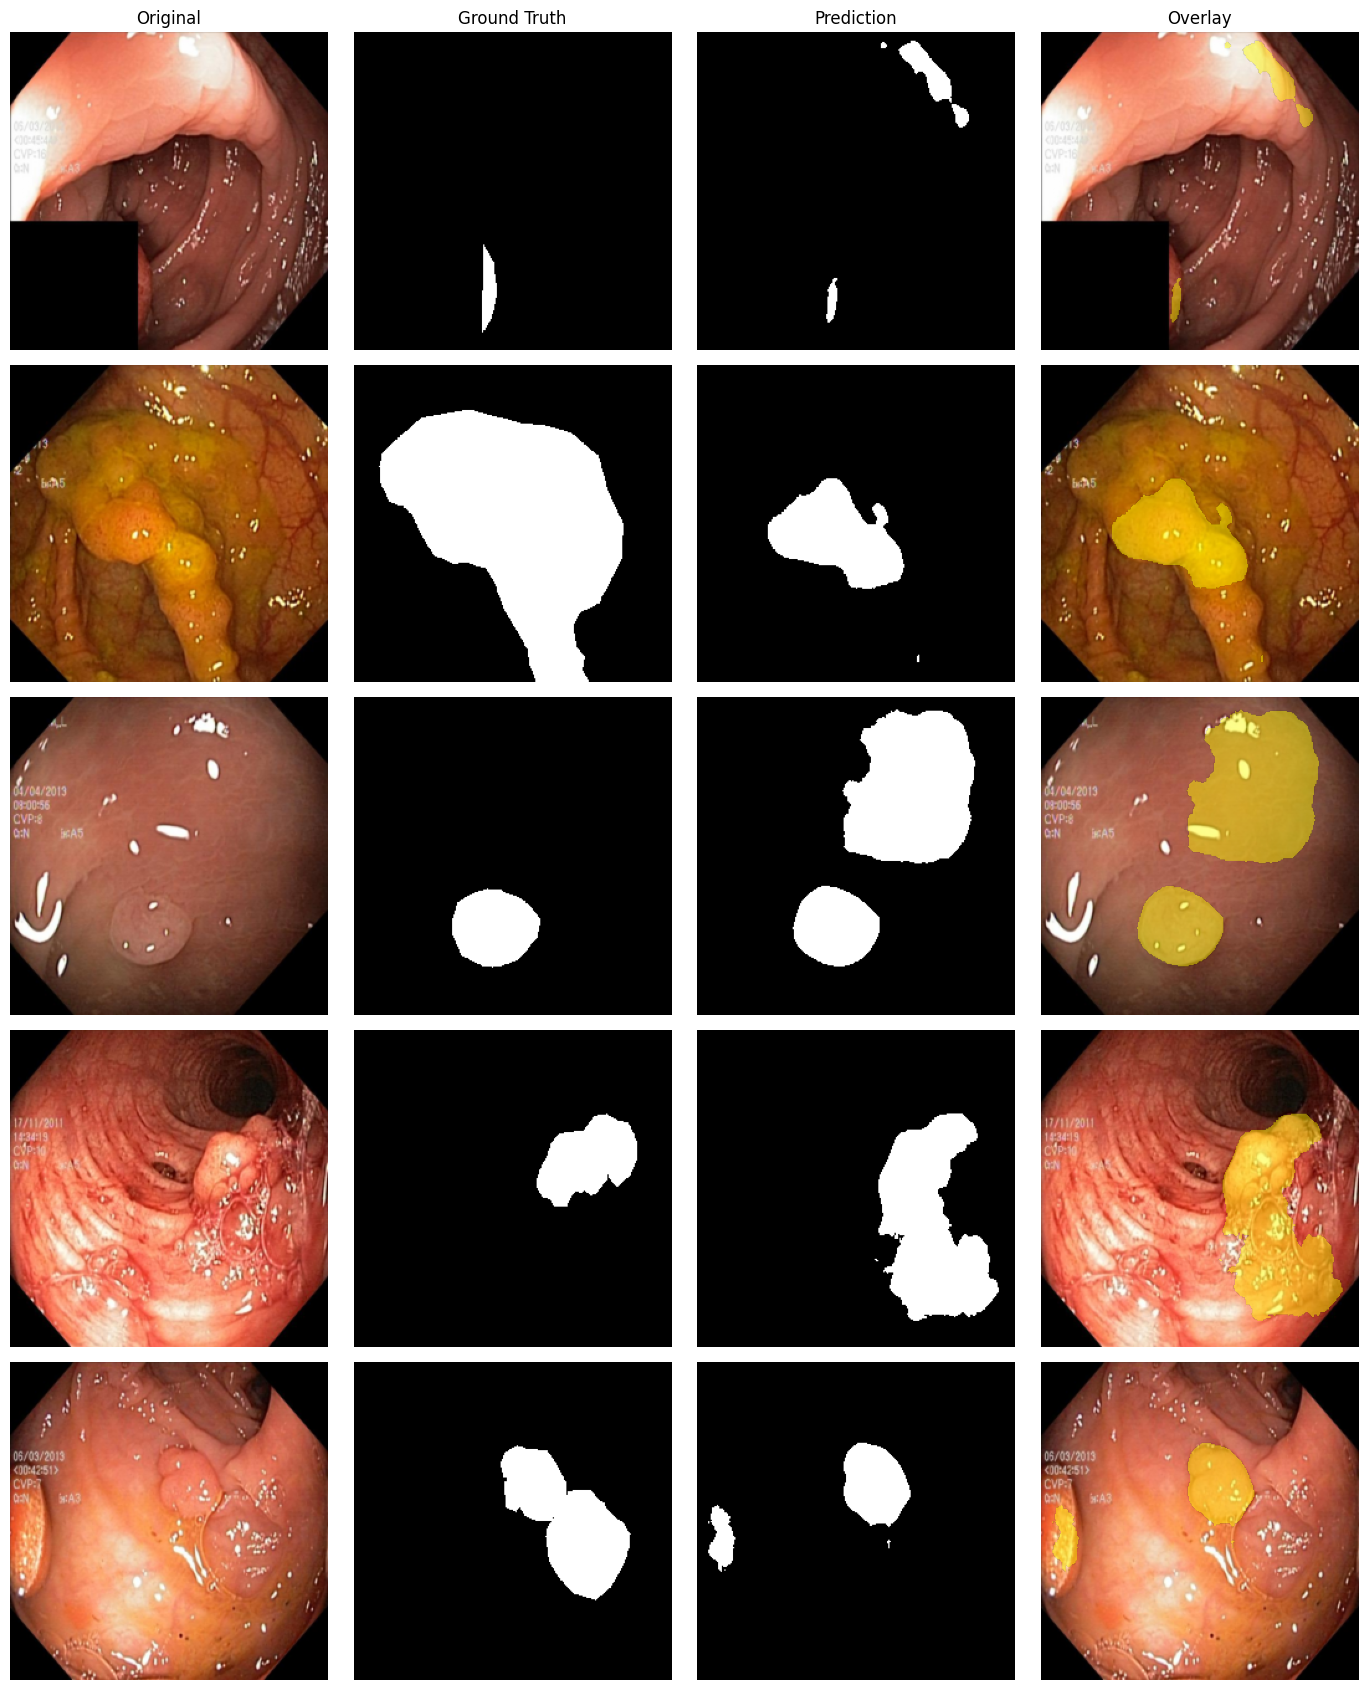

Saved to: /content/drive/MyDrive/polyp-segmentation/results/worst_predictions.png


In [50]:

import csv
from pathlib import Path

import torch
import matplotlib.pyplot as plt
import numpy as np
import segmentation_models_pytorch as smp

from src.dataset import PolypDataset

DRIVE = Path("/content/drive/MyDrive/polyp-segmentation")
IMAGE_DIR = Path("data/Kvasir-SEG/images")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Read the five lowest-scoring images
with open(DRIVE / "results/test_metrics.csv") as f:
    records = list(csv.DictReader(f))

worst = sorted(records, key=lambda r: float(r["dice"]))[:5]

# Reconstruct the model and load its trained weights
model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None,
).to(device)

checkpoint = torch.load(
    DRIVE / "checkpoints/bce_dice_best.pt",
    map_location=device,
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Same normalization used during training
mean = torch.tensor(
    [0.485, 0.456, 0.406], device=device
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=device
).view(3, 1, 1)

paths = [IMAGE_DIR / r["image"] for r in worst]
dataset = PolypDataset(paths)

fig, axes = plt.subplots(5, 4, figsize=(14, 17))

with torch.inference_mode():
    for i, record in enumerate(worst):
        image_tensor, mask_tensor = dataset[i]

        # Normalize and add batch dimension
        x = ((image_tensor.to(device) - mean) / std).unsqueeze(0)

        logits = model(x)
        prediction = (logits > 0).squeeze().cpu().numpy()

        image = image_tensor.permute(1, 2, 0).numpy()
        mask = mask_tensor.squeeze().numpy()

        # Original
        axes[i, 0].imshow(image)

        # Ground truth
        axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)

        # Predicted mask
        axes[i, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)

        # Overlay predicted foreground on original image
        axes[i, 3].imshow(image)
        overlay = np.ma.masked_where(~prediction, prediction)
        axes[i, 3].imshow(
            overlay, cmap="autumn", alpha=0.45, vmin=0, vmax=1
        )

        axes[i, 0].set_ylabel(
            f"Dice: {float(record['dice']):.3f}",
            fontsize=11,
        )

        for ax in axes[i]:
            ax.axis("off")

for ax, title in zip(
    axes[0],
    ["Original", "Ground Truth", "Prediction", "Overlay"],
):
    ax.set_title(title)

plt.tight_layout()

output = DRIVE / "results/worst_predictions.png"
plt.savefig(output, dpi=150, bbox_inches="tight")
plt.show()

print("Saved to:", output)


In [53]:
!python -u -m src.benchmark

Running FP32 benchmark...
Running mixed-precision benchmark...

FP32 results: {'mean_ms': 7.919074554443359, 'median_ms': 7.691839933395386, 'dice': 0.8521433011041437, 'iou': 0.7675105674263862}
Mixed precision results: {'mean_ms': 5.468934392929077, 'median_ms': 5.334223985671997, 'dice': 0.852163669029888, 'iou': 0.7675340835034637}

Median latency speedup: 1.44x
Results saved to: /content/drive/MyDrive/polyp-segmentation/results/optimization.csv


In [54]:
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Tesla T4, 15360 MiB
